In [1]:
# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import os
import time
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from imblearn.over_sampling import (
    SMOTE,
    ADASYN
)

from imblearn.under_sampling import (
    RandomUnderSampler,
    TomekLinks
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

print("Library berhasil di-import.")

Library berhasil di-import.


In [2]:
# ============================================================
# 2. KONFIGURASI PENELITIAN
# ============================================================

RANDOM_SEED = 2024

TEST_SIZE = 0.20

N_ESTIMATORS = 100

SEEDS = [42, 123, 2024]

print("Random seed :", RANDOM_SEED)
print("Test size   :", TEST_SIZE)
print("Seeds       :", SEEDS)

Random seed : 2024
Test size   : 0.2
Seeds       : [42, 123, 2024]


In [3]:
# ============================================================
# 3. LOAD FINAL DATASET - 20 FEATURES
# ============================================================

FINAL_DATA_FILE = "CIC-IDS2017_20features_clean.csv"

print("Loading final dataset...")

df = pd.read_csv(FINAL_DATA_FILE)

print("Dataset berhasil dimuat.")
print("Shape:", df.shape)

print("\nKolom:")
print(df.columns.tolist())

Loading final dataset...
Dataset berhasil dimuat.
Shape: (1265086, 21)

Kolom:
['Avg Packet Size', 'Bwd Packet Length Mean', 'Avg Bwd Segment Size', 'Subflow Bwd Bytes', 'Bwd Packets Length Total', 'Bwd Packet Length Max', 'Packet Length Std', 'Packet Length Variance', 'Fwd IAT Max', 'Packet Length Mean', 'Fwd IAT Total', 'Fwd Packets Length Total', 'Subflow Fwd Bytes', 'Packet Length Max', 'Bwd Packet Length Std', 'Init Bwd Win Bytes', 'Fwd Packet Length Max', 'Init Fwd Win Bytes', 'Fwd IAT Mean', 'Fwd Packet Length Std', 'Label']


In [4]:
# ============================================================
# 4. VALIDASI LABEL
# ============================================================

if "Label" not in df.columns:
    raise ValueError("Kolom Label tidak ditemukan.")

print("Unique label:")
print(df["Label"].unique())

print("\nDistribusi label:")
print(df["Label"].value_counts())

print("\nDistribusi persentase:")
print(
    df["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Unique label:
[0 1]

Distribusi label:
Label
0    943316
1    321770
Name: count, dtype: int64

Distribusi persentase:
Label
0    74.57
1    25.43
Name: proportion, dtype: float64


In [5]:
# ============================================================
# 5. VALIDASI INFINITE DAN MISSING VALUES
# ============================================================

df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

print("Total missing values:", df.isna().sum().sum())

if df.isna().sum().sum() > 0:
    print("Terdapat missing values.")
    df.dropna(inplace=True)

print("Shape setelah validasi:", df.shape)

Total missing values: 0
Shape setelah validasi: (1265086, 21)


In [6]:
# ============================================================
# 10. VALIDASI LABEL
# ============================================================

print("Unique label:")
print(df["Label"].unique())

print("\nDistribusi label:")
print(df["Label"].value_counts())

print("\nDistribusi persentase:")
print(
    df["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Unique label:
[0 1]

Distribusi label:
Label
0    943316
1    321770
Name: count, dtype: int64

Distribusi persentase:
Label
0    74.57
1    25.43
Name: proportion, dtype: float64


In [7]:
# ============================================================
# 6. GUNAKAN 20 FITUR HASIL MUTUAL INFORMATION
# ============================================================

selected_features = [
    "Avg Packet Size",
    "Bwd Packet Length Mean",
    "Avg Bwd Segment Size",
    "Subflow Bwd Bytes",
    "Bwd Packets Length Total",
    "Bwd Packet Length Max",
    "Packet Length Std",
    "Packet Length Variance",
    "Fwd IAT Max",
    "Packet Length Mean",
    "Fwd IAT Total",
    "Fwd Packets Length Total",
    "Subflow Fwd Bytes",
    "Packet Length Max",
    "Bwd Packet Length Std",
    "Init Bwd Win Bytes",
    "Fwd Packet Length Max",
    "Init Fwd Win Bytes",
    "Fwd IAT Mean",
    "Fwd Packet Length Std"
]

# Validasi fitur
missing_features = [
    col for col in selected_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Fitur tidak ditemukan: {missing_features}"
    )

X = df[selected_features].copy()
y = df["Label"].copy()

# Hemat RAM
X = X.astype(np.float32)
y = y.astype(np.int8)

print("Jumlah fitur:", X.shape[1])
print("Jumlah data :", X.shape[0])

print("\nShape X:", X.shape)
print("Shape y:", y.shape)

print("\n20 fitur yang digunakan:")
for i, feature in enumerate(selected_features, 1):
    print(f"{i:2}. {feature}")

Jumlah fitur: 20
Jumlah data : 1265086

Shape X: (1265086, 20)
Shape y: (1265086,)

20 fitur yang digunakan:
 1. Avg Packet Size
 2. Bwd Packet Length Mean
 3. Avg Bwd Segment Size
 4. Subflow Bwd Bytes
 5. Bwd Packets Length Total
 6. Bwd Packet Length Max
 7. Packet Length Std
 8. Packet Length Variance
 9. Fwd IAT Max
10. Packet Length Mean
11. Fwd IAT Total
12. Fwd Packets Length Total
13. Subflow Fwd Bytes
14. Packet Length Max
15. Bwd Packet Length Std
16. Init Bwd Win Bytes
17. Fwd Packet Length Max
18. Init Fwd Win Bytes
19. Fwd IAT Mean
20. Fwd Packet Length Std


In [8]:
# ============================================================
# 12. CHECK DUPLICATES
# ============================================================

duplicate_count = X.duplicated().sum()

print(
    "Jumlah duplicate feature rows:",
    duplicate_count
)

Jumlah duplicate feature rows: 478201


In [9]:
# ============================================================
# 13. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

print("\nTrain distribution:")
print(y_train.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())

Train shape: (1012068, 20)
Test shape : (253018, 20)

Train distribution:
Label
0    754652
1    257416
Name: count, dtype: int64

Test distribution:
Label
0    188664
1     64354
Name: count, dtype: int64


In [10]:
# ============================================================
# DIAGNOSTIC: TRAIN-TEST IDENTICAL FEATURE OVERLAP
# ============================================================

train_keys = set(map(tuple, X_train.to_numpy()))

test_keys = list(map(tuple, X_test.to_numpy()))

overlap_count = sum(
    key in train_keys
    for key in test_keys
)

print("Jumlah data TEST              :", len(X_test))
print("Test yang identik dengan TRAIN:", overlap_count)
print(
    "Persentase overlap            :",
    round(
        overlap_count / len(X_test) * 100,
        2
    ),
    "%"
)

Jumlah data TEST              : 253018
Test yang identik dengan TRAIN: 102875
Persentase overlap            : 40.66 %


In [11]:
# ============================================================
# DIAGNOSTIC: CONFLICTING DUPLICATES
# ============================================================

duplicate_label_check = (
    df.groupby(selected_features)["Label"]
    .nunique()
)

conflicting_duplicates = (
    duplicate_label_check > 1
).sum()

print(
    "Duplicate feature groups dengan label berbeda:",
    conflicting_duplicates
)

Duplicate feature groups dengan label berbeda: 91


In [12]:
duplicate_groups = (
    df.groupby(selected_features)["Label"]
    .agg(["count", "nunique"])
)

print("Jumlah kelompok duplicate:",
      (duplicate_groups["count"] > 1).sum())

print("Duplicate groups dengan label berbeda:",
      (duplicate_groups["nunique"] > 1).sum())

Jumlah kelompok duplicate: 45022
Duplicate groups dengan label berbeda: 91


In [13]:
# ============================================================
# OVERLAP CONSISTENCY CHECK
# ============================================================

train_df = pd.DataFrame(
    X_train,
    columns=selected_features
)
train_df["Label"] = y_train.values

test_df = pd.DataFrame(
    X_test,
    columns=selected_features
)
test_df["Label"] = y_test.values

# Label yang muncul pada TRAIN untuk setiap feature vector
train_label_map = (
    train_df
    .groupby(selected_features)["Label"]
    .agg(list)
)

overlap_consistent = 0
overlap_conflicting = 0

for _, row in test_df.iterrows():

    key = tuple(row[selected_features])

    if key in train_keys:

        train_labels = train_label_map.loc[key]

        if row["Label"] in train_labels:
            overlap_consistent += 1
        else:
            overlap_conflicting += 1

print("Overlap konsisten :", overlap_consistent)
print("Overlap konflik   :", overlap_conflicting)

Overlap konsisten : 102844
Overlap konflik   : 31


In [14]:
# ============================================================
# 14. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    X_test,
    y_test,
    model_name,
    handling_name,
    seed,
    training_time
):
    
    y_pred = model.predict(X_test)
    
    # Probabilitas kelas 1
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )
    
    if y_prob is not None:
        roc_auc = roc_auc_score(
            y_test,
            y_prob
        )
        
        pr_auc = average_precision_score(
            y_test,
            y_prob
        )
    else:
        roc_auc = np.nan
        pr_auc = np.nan
    
    result = {
        "Model": model_name,
        "Handling": handling_name,
        "Seed": seed,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Training_Time_sec": training_time
    }
    
    return result

In [15]:
# ============================================================
# 15. RANDOM FOREST MODEL
# ============================================================

def create_rf(
    seed=42,
    class_weight=None
):
    
    model = RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        random_state=seed,
        n_jobs=1,
        class_weight=class_weight
    )
    
    return model

In [16]:
# ============================================================
# 16. XGBOOST MODEL
# ============================================================

def create_xgb(seed=42):
    
    model = XGBClassifier(
        n_estimators=200,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=seed,
        n_jobs=1
    )
    
    return model

In [17]:
# ============================================================
# 17. BALANCED SAMPLE WEIGHT
# ============================================================

def create_balanced_sample_weight(y):
    
    class_counts = y.value_counts()
    
    n_samples = len(y)
    n_classes = len(class_counts)
    
    weights = {}
    
    for cls, count in class_counts.items():
        weights[cls] = n_samples / (
            n_classes * count
        )
    
    sample_weights = y.map(weights).values
    
    return sample_weights

In [18]:
# ============================================================
# 18. RESULT STORAGE
# ============================================================

results = []

rf_models = {}
xgb_models = {}
print("Result storage siap.")

Result storage siap.


In [19]:
# ============================================================
# 19. RUN RANDOM FOREST EXPERIMENT
# ============================================================

def run_rf_experiment(
    X_train,
    y_train,
    X_test,
    y_test,
    handling,
    seed
):
    
    print("\n" + "=" * 70)
    print(f"Random Forest | {handling} | Seed {seed}")
    print("=" * 70)
    
    X_train_exp = X_train
    y_train_exp = y_train
    
    class_weight = None
    
    # --------------------------------------------------------
    # CLASS WEIGHT
    # --------------------------------------------------------
    
    if handling == "Class Weight":
        
        print("Menggunakan Class Weight = balanced...")
        
        class_weight = "balanced"
    
    # --------------------------------------------------------
    # SMOTE
    # --------------------------------------------------------
    
    elif handling == "SMOTE":
        
        print("Menjalankan SMOTE...")
        
        sampler = SMOTE(
            random_state=seed
        )
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah SMOTE:",
            X_train_exp.shape
        )
        
    # --------------------------------------------------------
    # ADASYN
    # --------------------------------------------------------
    
    elif handling == "ADASYN":
        
        print("Menjalankan ADASYN...")
        
        sampler = ADASYN(
            random_state=seed
        )
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah ADASYN:",
            X_train_exp.shape
        )
        
    # --------------------------------------------------------
    # RANDOM UNDERSAMPLING
    # --------------------------------------------------------
    
    elif handling == "Random Undersampling":
        
        print("Menjalankan Random Undersampling...")
        
        sampler = RandomUnderSampler(
            random_state=seed
        )
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah Random Undersampling:",
            X_train_exp.shape
        )
        
    # --------------------------------------------------------
    # TOMEK LINKS
    # --------------------------------------------------------
    
    elif handling == "Tomek Links":
        
        print("Menjalankan Tomek Links...")
        
        sampler = TomekLinks()
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah Tomek Links:",
            X_train_exp.shape
        )
        
    # --------------------------------------------------------
    # DISTRIBUSI DATA TRAINING
    # --------------------------------------------------------
    
    print("\nDistribusi label training:")
    print(
        pd.Series(y_train_exp)
        .value_counts()
        .sort_index()
    )
    
    # --------------------------------------------------------
    # MODEL
    # --------------------------------------------------------
    
    model = create_rf(
        seed=seed,
        class_weight=class_weight
    )
    
    start_time = time.time()
    
    model.fit(
        X_train_exp,
        y_train_exp
    )
    
    training_time = time.time() - start_time
    
    # --------------------------------------------------------
    # EVALUATION
    # --------------------------------------------------------
    
    result = evaluate_model(
        model=model,
        X_test=X_test,
        y_test=y_test,
        model_name="Random Forest",
        handling_name=handling,
        seed=seed,
        training_time=training_time
    )
    
    print("\nAccuracy :", result["Accuracy"])
    print("Precision:", result["Precision"])
    print("Recall   :", result["Recall"])
    print("F1       :", result["F1"])
    print("ROC-AUC  :", result["ROC_AUC"])
    print("PR-AUC   :", result["PR_AUC"])
    print("Time     :", result["Training_Time_sec"])
    
    return model, result

In [20]:
# ============================================================
# 20A. RANDOM FOREST - NONE
# ============================================================

handling = "None"
seed = 42

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model


Random Forest | None | Seed 42

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995099162905406
Precision: 0.9991917182205365
Recall   : 0.9988811884265159
F1       : 0.9990364291930871
ROC-AUC  : 0.9999317227432903
PR-AUC   : 0.9998832565214788
Time     : 185.366952419281


In [21]:
# ============================================================
# 20B. RANDOM FOREST - CLASS WEIGHT
# ============================================================

handling = "Class Weight"
seed = 42

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model


Random Forest | Class Weight | Seed 42
Menggunakan Class Weight = balanced...

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995415345943767
Precision: 0.9992694149101535
Recall   : 0.998927805575411
F1       : 0.9990985810422268
ROC-AUC  : 0.9999237047274389
PR-AUC   : 0.9998711380240098
Time     : 165.9228711128235


In [22]:
# ============================================================
# 20C. RANDOM FOREST - SMOTE
# ============================================================

handling = "SMOTE"
seed = 42

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model


Random Forest | SMOTE | Seed 42
Menjalankan SMOTE...


  File "C:\Users\brene\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

Shape setelah SMOTE: (1509304, 20)

Distribusi label training:
Label
0    754652
1    754652
Name: count, dtype: int64

Accuracy : 0.9994901548506431
Precision: 0.9988504497227099
Recall   : 0.9991453522702551
F1       : 0.998997879232795
ROC-AUC  : 0.9999231101032986
PR-AUC   : 0.999870506523627
Time     : 326.47927498817444


In [23]:
# ============================================================
# 20D. RANDOM FOREST - ADASYN
# ============================================================

handling = "ADASYN"
seed = 42

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model


Random Forest | ADASYN | Seed 42
Menjalankan ADASYN...
Shape setelah ADASYN: (1511793, 20)

Distribusi label training:
Label
0    754652
1    757141
Name: count, dtype: int64

Accuracy : 0.9993202064675241
Precision: 0.9981527475939149
Recall   : 0.9991764303695186
F1       : 0.9986643266497895
ROC-AUC  : 0.9999007888215402
PR-AUC   : 0.9997430247619284
Time     : 284.942156791687


In [24]:
# ============================================================
# 20E. RANDOM FOREST - RANDOM UNDERSAMPLING
# ============================================================

handling = "Random Undersampling"
seed = 42

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model


Random Forest | Random Undersampling | Seed 42
Menjalankan Random Undersampling...
Shape setelah Random Undersampling: (514832, 20)

Distribusi label training:
Label
0    257416
1    257416
Name: count, dtype: int64

Accuracy : 0.9993913476511552
Precision: 0.9982151171814372
Recall   : 0.9993939770643627
F1       : 0.9988041992794136
ROC-AUC  : 0.9999617950592322
PR-AUC   : 0.9999257823341764
Time     : 52.623788356781006


In [25]:
# ============================================================
# 20F. RANDOM FOREST - TOMEK LINKS
# ============================================================

handling = "Tomek Links"
seed = 42

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model


Random Forest | Tomek Links | Seed 42
Menjalankan Tomek Links...
Shape setelah Tomek Links: (1010920, 20)

Distribusi label training:
Label
0    753504
1    257416
Name: count, dtype: int64

Accuracy : 0.9995454868823562
Precision: 0.9991608000372978
Recall   : 0.9990521179724648
F1       : 0.9991064560492926
ROC-AUC  : 0.9999395347265513
PR-AUC   : 0.9998945163615077
Time     : 154.50933146476746


In [26]:
# ============================================================
# 20A. RANDOM FOREST - NONE
# ============================================================

handling = "None"
seed = 123

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model





Random Forest | None | Seed 123

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9994782979867045
Precision: 0.9991140263616016
Recall   : 0.9988345712776207
F1       : 0.998974279275779
ROC-AUC  : 0.9999315373016043
PR-AUC   : 0.9998826061511688
Time     : 152.81243062019348


In [27]:
# ============================================================
# 20B. RANDOM FOREST - CLASS WEIGHT
# ============================================================

handling = "Class Weight"
seed = 123

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model




Random Forest | Class Weight | Seed 123
Menggunakan Class Weight = balanced...

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995375823063972
Precision: 0.9991918061578154
Recall   : 0.998989961773938
F1       : 0.9990908737713198
ROC-AUC  : 0.9999236681579925
PR-AUC   : 0.9998709217124615
Time     : 150.518306016922


In [28]:

# ============================================================
# 20C. RANDOM FOREST - SMOTE
# ============================================================

handling = "SMOTE"
seed = 123

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model




Random Forest | SMOTE | Seed 123
Menjalankan SMOTE...
Shape setelah SMOTE: (1509304, 20)

Distribusi label training:
Label
0    754652
1    754652
Name: count, dtype: int64

Accuracy : 0.999466441122766
Precision: 0.9988658432377845
Recall   : 0.999036578922833
F1       : 0.998951203784989
ROC-AUC  : 0.9999125891806404
PR-AUC   : 0.999843428547888
Time     : 295.5263555049896


In [29]:

# ============================================================
# 20D. RANDOM FOREST - ADASYN
# ============================================================

handling = "ADASYN"
seed = 123

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model





Random Forest | ADASYN | Seed 123
Menjalankan ADASYN...
Shape setelah ADASYN: (1511793, 20)

Distribusi label training:
Label
0    754652
1    757141
Name: count, dtype: int64

Accuracy : 0.9993281110434831
Precision: 0.9981837374646838
Recall   : 0.9991764303695186
F1       : 0.9986798372316963
ROC-AUC  : 0.9999007250309179
PR-AUC   : 0.999742903860308
Time     : 282.7243514060974


In [30]:
# ============================================================
# 20E. RANDOM FOREST - RANDOM UNDERSAMPLING
# ============================================================

handling = "Random Undersampling"
seed = 123

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model





Random Forest | Random Undersampling | Seed 123
Menjalankan Random Undersampling...
Shape setelah Random Undersampling: (514832, 20)

Distribusi label training:
Label
0    257416
1    257416
Name: count, dtype: int64

Accuracy : 0.9993913476511552
Precision: 0.9982769861227531
Recall   : 0.9993318208658358
F1       : 0.9988041249922346
ROC-AUC  : 0.9999539028538071
PR-AUC   : 0.9999146192329457
Time     : 52.37590932846069


In [31]:
# ============================================================
# 20F. RANDOM FOREST - TOMEK LINKS
# ============================================================

handling = "Tomek Links"
seed = 123

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model



Random Forest | Tomek Links | Seed 123
Menjalankan Tomek Links...
Shape setelah Tomek Links: (1010920, 20)

Distribusi label training:
Label
0    753504
1    257416
Name: count, dtype: int64

Accuracy : 0.9995336300184177
Precision: 0.9991607609101082
Recall   : 0.9990055008235696
F1       : 0.9990831248348848
ROC-AUC  : 0.999916073820592
PR-AUC   : 0.9998605003915929
Time     : 153.80738592147827


In [32]:
# ============================================================
# 20A. RANDOM FOREST - NONE
# ============================================================

handling = "None"
seed = 2024

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model




Random Forest | None | Seed 2024

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995257254424587
Precision: 0.9991917684727533
Recall   : 0.9989433446250428
F1       : 0.9990675411058962
ROC-AUC  : 0.999931543849512
PR-AUC   : 0.9998826018089618
Time     : 149.82405161857605


In [33]:

# ============================================================
# 20B. RANDOM FOREST - CLASS WEIGHT
# ============================================================

handling = "Class Weight"
seed = 2024

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model




Random Forest | Class Weight | Seed 2024
Menggunakan Class Weight = balanced...

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995454868823562
Precision: 0.9992383853769993
Recall   : 0.9989744227243061
F1       : 0.9991063866160027
ROC-AUC  : 0.999923702297712
PR-AUC   : 0.999871231344203
Time     : 151.6938395500183


In [34]:

# ============================================================
# 20C. RANDOM FOREST - SMOTE
# ============================================================

handling = "SMOTE"
seed = 2024

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model




Random Forest | SMOTE | Seed 2024
Menjalankan SMOTE...
Shape setelah SMOTE: (1509304, 20)

Distribusi label training:
Label
0    754652
1    754652
Name: count, dtype: int64

Accuracy : 0.9994545842588274
Precision: 0.9987882930466663
Recall   : 0.9990676570220965
F1       : 0.9989279555023849
ROC-AUC  : 0.9999206790587487
PR-AUC   : 0.9998554660723015
Time     : 289.3868610858917


In [35]:

# ============================================================
# 20D. RANDOM FOREST - ADASYN
# ============================================================

handling = "ADASYN"
seed = 2024

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model




Random Forest | ADASYN | Seed 2024
Menjalankan ADASYN...
Shape setelah ADASYN: (1511793, 20)

Distribusi label training:
Label
0    754652
1    757141
Name: count, dtype: int64

Accuracy : 0.9993281110434831
Precision: 0.9981837374646838
Recall   : 0.9991764303695186
F1       : 0.9986798372316963
ROC-AUC  : 0.9999163290654443
PR-AUC   : 0.9997644725598377
Time     : 282.13042664527893


In [36]:

# ============================================================
# 20E. RANDOM FOREST - RANDOM UNDERSAMPLING
# ============================================================

handling = "Random Undersampling"
seed = 2024

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model




Random Forest | Random Undersampling | Seed 2024
Menjalankan Random Undersampling...
Shape setelah Random Undersampling: (514832, 20)

Distribusi label training:
Label
0    257416
1    257416
Name: count, dtype: int64

Accuracy : 0.9993518247713601
Precision: 0.9981065896886737
Recall   : 0.9993473599154675
F1       : 0.9987265894337982
ROC-AUC  : 0.9999462529209647
PR-AUC   : 0.9999040202424996
Time     : 52.421350955963135


In [37]:

# ============================================================
# 20F. RANDOM FOREST - TOMEK LINKS
# ============================================================

handling = "Tomek Links"
seed = 2024

model, result = run_rf_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

rf_models[f"{handling}_seed_{seed}"] = model



Random Forest | Tomek Links | Seed 2024
Menjalankan Tomek Links...
Shape setelah Tomek Links: (1010920, 20)

Distribusi label training:
Label
0    753504
1    257416
Name: count, dtype: int64

Accuracy : 0.9995178208664997
Precision: 0.9990986510847268
Recall   : 0.9990055008235696
F1       : 0.9990520737828472
ROC-AUC  : 0.9999239723268337
PR-AUC   : 0.999872181425646
Time     : 148.86555123329163


In [38]:
# ============================================================
# 21. RUN XGBOOST EXPERIMENT
# ============================================================

def run_xgb_experiment(
    X_train,
    y_train,
    X_test,
    y_test,
    handling,
    seed
):
    
    print("\n" + "=" * 70)
    print(f"XGBoost | {handling} | Seed {seed}")
    print("=" * 70)
    
    X_train_exp = X_train
    y_train_exp = y_train
    
    sample_weight = None
    
    # --------------------------------------------------------
    # CLASS WEIGHT
    # --------------------------------------------------------
    
    if handling == "Class Weight":
        
        print("Menggunakan balanced sample weights...")
        
        sample_weight = create_balanced_sample_weight(
            y_train
        )
    
    # --------------------------------------------------------
    # SMOTE
    # --------------------------------------------------------
    
    elif handling == "SMOTE":
        
        print("Menjalankan SMOTE...")
        
        sampler = SMOTE(
            random_state=seed
        )
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah SMOTE:",
            X_train_exp.shape
        )
    
    # --------------------------------------------------------
    # ADASYN
    # --------------------------------------------------------
    
    elif handling == "ADASYN":
        
        print("Menjalankan ADASYN...")
        
        sampler = ADASYN(
            random_state=seed
        )
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah ADASYN:",
            X_train_exp.shape
        )
    
    # --------------------------------------------------------
    # RANDOM UNDERSAMPLING
    # --------------------------------------------------------
    
    elif handling == "Random Undersampling":
        
        print("Menjalankan Random Undersampling...")
        
        sampler = RandomUnderSampler(
            random_state=seed
        )
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah Random Undersampling:",
            X_train_exp.shape
        )
    
    # --------------------------------------------------------
    # TOMEK LINKS
    # --------------------------------------------------------
    
    elif handling == "Tomek Links":
        
        print("Menjalankan Tomek Links...")
        
        sampler = TomekLinks()
        
        X_train_exp, y_train_exp = sampler.fit_resample(
            X_train,
            y_train
        )
        
        print(
            "Shape setelah Tomek Links:",
            X_train_exp.shape
        )
    
    # --------------------------------------------------------
    # DISTRIBUSI DATA TRAINING
    # --------------------------------------------------------
    
    print("\nDistribusi label training:")
    print(
        pd.Series(y_train_exp)
        .value_counts()
        .sort_index()
    )
    
    # --------------------------------------------------------
    # MODEL
    # --------------------------------------------------------
    
    model = create_xgb(
        seed=seed
    )
    
    start_time = time.time()
    
    if handling == "Class Weight":
        
        model.fit(
            X_train_exp,
            y_train_exp,
            sample_weight=sample_weight
        )
        
    else:
        
        model.fit(
            X_train_exp,
            y_train_exp
        )
    
    training_time = time.time() - start_time
    
    # --------------------------------------------------------
    # EVALUATION
    # --------------------------------------------------------
    
    result = evaluate_model(
        model=model,
        X_test=X_test,
        y_test=y_test,
        model_name="XGBoost",
        handling_name=handling,
        seed=seed,
        training_time=training_time
    )
    
    print("\nAccuracy :", result["Accuracy"])
    print("Precision:", result["Precision"])
    print("Recall   :", result["Recall"])
    print("F1       :", result["F1"])
    print("ROC-AUC  :", result["ROC_AUC"])
    print("PR-AUC   :", result["PR_AUC"])
    print("Time     :", result["Training_Time_sec"])
    
    return model, result

In [39]:
# ============================================================
# 22A. XGBOOST - NONE
# ============================================================

handling = "None"
seed = 42

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model


XGBoost | None | Seed 42

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995731528982128
Precision: 0.998804347826087
Recall   : 0.9995182894614165
F1       : 0.9991611911086258
ROC-AUC  : 0.9999923464019765
PR-AUC   : 0.999979321943501
Time     : 22.71859335899353


In [40]:
# ============================================================
# 22B. XGBOOST - CLASS WEIGHT
# ============================================================

handling = "Class Weight"
seed = 42

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model


XGBoost | Class Weight | Seed 42
Menggunakan balanced sample weights...

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995652483222538
Precision: 0.9986184843686939
Recall   : 0.9996736799577338
F1       : 0.9991458035658819
ROC-AUC  : 0.9999894858723406
PR-AUC   : 0.999975305282628
Time     : 22.706523180007935


In [41]:
# ============================================================
# 22C. XGBOOST - SMOTE
# ============================================================

handling = "SMOTE"
seed = 42

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model


XGBoost | SMOTE | Seed 42
Menjalankan SMOTE...
Shape setelah SMOTE: (1509304, 20)

Distribusi label training:
Label
0    754652
1    754652
Name: count, dtype: int64

Accuracy : 0.9994308705309504
Precision: 0.9982153941651148
Recall   : 0.99954936756068
F1       : 0.9988819354938895
ROC-AUC  : 0.9999900786021177
PR-AUC   : 0.9999748016583196
Time     : 33.7736120223999


In [42]:
# ============================================================
# 22D. XGBOOST - ADASYN
# ============================================================

handling = "ADASYN"
seed = 42

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model


XGBoost | ADASYN | Seed 42
Menjalankan ADASYN...
Shape setelah ADASYN: (1511793, 20)

Distribusi label training:
Label
0    754652
1    757141
Name: count, dtype: int64

Accuracy : 0.9988064090301876
Precision: 0.995605075827917
Recall   : 0.9997202971066289
F1       : 0.9976584427869183
ROC-AUC  : 0.999985458497328
PR-AUC   : 0.999962035681732
Time     : 33.16706299781799


In [43]:
# ============================================================
# 22E. XGBOOST - RANDOM UNDERSAMPLING
# ============================================================

handling = "Random Undersampling"
seed = 42

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model


XGBoost | Random Undersampling | Seed 42
Menjalankan Random Undersampling...
Shape setelah Random Undersampling: (514832, 20)

Distribusi label training:
Label
0    257416
1    257416
Name: count, dtype: int64

Accuracy : 0.9994032045150938
Precision: 0.997983339279897
Recall   : 0.9996736799577338
F1       : 0.9988277944681214
ROC-AUC  : 0.9999909498444692
PR-AUC   : 0.9999760225742791
Time     : 10.730875968933105


In [44]:
# ============================================================
# 22F. XGBOOST - TOMEK LINKS
# ============================================================

handling = "Tomek Links"
seed = 42

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model


XGBoost | Tomek Links | Seed 42
Menjalankan Tomek Links...
Shape setelah Tomek Links: (1010920, 20)

Distribusi label training:
Label
0    753504
1    257416
Name: count, dtype: int64

Accuracy : 0.9995178208664997
Precision: 0.9985872636383395
Recall   : 0.9995182894614165
F1       : 0.9990525596421471
ROC-AUC  : 0.9999911043586166
PR-AUC   : 0.9999747419965631
Time     : 22.981409788131714


In [45]:
# ============================================================
# 22A. XGBOOST - NONE
# ============================================================

handling = "None"
seed = 123

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model




XGBoost | None | Seed 123

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995692006102332
Precision: 0.9987888386826291
Recall   : 0.9995182894614165
F1       : 0.999153430934721
ROC-AUC  : 0.9999915662126048
PR-AUC   : 0.9999776134443483
Time     : 22.16324234008789


In [46]:

# ============================================================
# 22B. XGBOOST - CLASS WEIGHT
# ============================================================

handling = "Class Weight"
seed = 123

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model



XGBoost | Class Weight | Seed 123
Menggunakan balanced sample weights...

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995850097621513
Precision: 0.998680513513094
Recall   : 0.9996892190073655
F1       : 0.9991846116810201
ROC-AUC  : 0.9999894222464457
PR-AUC   : 0.99997530250438
Time     : 22.363186359405518


In [47]:


# ============================================================
# 22C. XGBOOST - SMOTE
# ============================================================

handling = "SMOTE"
seed = 123

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model




XGBoost | SMOTE | Seed 123
Menjalankan SMOTE...
Shape setelah SMOTE: (1509304, 20)

Distribusi label training:
Label
0    754652
1    754652
Name: count, dtype: int64

Accuracy : 0.9994585365468069
Precision: 0.9982001272323853
Recall   : 0.9996736799577338
F1       : 0.9989363601779462
ROC-AUC  : 0.9999904762948474
PR-AUC   : 0.9999753854998296
Time     : 34.214462757110596


In [48]:

# ============================================================
# 22D. XGBOOST - ADASYN
# ============================================================

handling = "ADASYN"
seed = 123

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model



XGBoost | ADASYN | Seed 123
Menjalankan ADASYN...
Shape setelah ADASYN: (1511793, 20)

Distribusi label training:
Label
0    754652
1    757141
Name: count, dtype: int64

Accuracy : 0.9987668861503924
Precision: 0.9954510289339316
Recall   : 0.9997202971066289
F1       : 0.9975810953296533
ROC-AUC  : 0.9999859208454978
PR-AUC   : 0.999962772358019
Time     : 32.95710802078247


In [49]:

# ============================================================
# 22E. XGBOOST - RANDOM UNDERSAMPLING
# ============================================================

handling = "Random Undersampling"
seed = 123

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model




XGBoost | Random Undersampling | Seed 123
Menjalankan Random Undersampling...
Shape setelah Random Undersampling: (514832, 20)

Distribusi label training:
Label
0    257416
1    257416
Name: count, dtype: int64

Accuracy : 0.9994782979867045
Precision: 0.9982621109145642
Recall   : 0.9996892190073655
F1       : 0.9989751552795031
ROC-AUC  : 0.9999913703931028
PR-AUC   : 0.9999772824398407
Time     : 10.739699602127075


In [50]:

# ============================================================
# 22F. XGBOOST - TOMEK LINKS
# ============================================================

handling = "Tomek Links"
seed = 123

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model



XGBoost | Tomek Links | Seed 123
Menjalankan Tomek Links...
Shape setelah Tomek Links: (1010920, 20)

Distribusi label training:
Label
0    753504
1    257416
Name: count, dtype: int64

Accuracy : 0.9995217731544791
Precision: 0.9986027665222859
Recall   : 0.9995182894614165
F1       : 0.9990603182492409
ROC-AUC  : 0.9999910665125341
PR-AUC   : 0.9999747603194362
Time     : 22.85495901107788


In [51]:
# ============================================================
# 22A. XGBOOST - NONE
# ============================================================

handling = "None"
seed = 2024

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model




XGBoost | None | Seed 2024

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995652483222538
Precision: 0.9987578411278802
Recall   : 0.9995338285110482
F1       : 0.9991456841516644
ROC-AUC  : 0.9999911102887972
PR-AUC   : 0.9999767367359016
Time     : 22.508745431900024


In [52]:

# ============================================================
# 22B. XGBOOST - CLASS WEIGHT
# ============================================================

handling = "Class Weight"
seed = 2024

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model




XGBoost | Class Weight | Seed 2024
Menggunakan balanced sample weights...

Distribusi label training:
Label
0    754652
1    257416
Name: count, dtype: int64

Accuracy : 0.9995889620501308
Precision: 0.9986960166413115
Recall   : 0.9996892190073655
F1       : 0.9991923710123318
ROC-AUC  : 0.9999905425975598
PR-AUC   : 0.9999771089228298
Time     : 22.64609169960022


In [53]:

# ============================================================
# 22C. XGBOOST - SMOTE
# ============================================================

handling = "SMOTE"
seed = 2024

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model




XGBoost | SMOTE | Seed 2024
Menjalankan SMOTE...
Shape setelah SMOTE: (1509304, 20)

Distribusi label training:
Label
0    754652
1    754652
Name: count, dtype: int64

Accuracy : 0.9994703934107455
Precision: 0.9983084515348086
Recall   : 0.9996115237592069
F1       : 0.9989595627057581
ROC-AUC  : 0.9999900226772211
PR-AUC   : 0.9999749763651985
Time     : 33.27172255516052


In [54]:

# ============================================================
# 22D. XGBOOST - ADASYN
# ============================================================

handling = "ADASYN"
seed = 2024

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model



XGBoost | ADASYN | Seed 2024
Menjalankan ADASYN...
Shape setelah ADASYN: (1511793, 20)

Distribusi label training:
Label
0    754652
1    757141
Name: count, dtype: int64

Accuracy : 0.9988380273340237
Precision: 0.9957283476753545
Recall   : 0.9997202971066289
F1       : 0.9977203293891413
ROC-AUC  : 0.9999871509049513
PR-AUC   : 0.9999657786657619
Time     : 32.94009709358215


In [55]:

# ============================================================
# 22E. XGBOOST - RANDOM UNDERSAMPLING
# ============================================================

handling = "Random Undersampling"
seed = 2024

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model




XGBoost | Random Undersampling | Seed 2024
Menjalankan Random Undersampling...
Shape setelah Random Undersampling: (514832, 20)

Distribusi label training:
Label
0    257416
1    257416
Name: count, dtype: int64

Accuracy : 0.9994822502746841
Precision: 0.9982776010551633
Recall   : 0.9996892190073655
F1       : 0.9989829113580074
ROC-AUC  : 0.9999919931856006
PR-AUC   : 0.9999791385434155
Time     : 10.771419763565063


In [56]:

# ============================================================
# 22F. XGBOOST - TOMEK LINKS
# ============================================================

handling = "Tomek Links"
seed = 2024

model, result = run_xgb_experiment(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    handling=handling,
    seed=seed
)

results.append(result)

xgb_models[f"{handling}_seed_{seed}"] = model



XGBoost | Tomek Links | Seed 2024
Menjalankan Tomek Links...
Shape setelah Tomek Links: (1010920, 20)

Distribusi label training:
Label
0    753504
1    257416
Name: count, dtype: int64

Accuracy : 0.9995059640025611
Precision: 0.9985407578744742
Recall   : 0.9995182894614165
F1       : 0.9990292845438802
ROC-AUC  : 0.9999913355532924
PR-AUC   : 0.9999756647824307
Time     : 22.345476388931274


In [57]:
results_df = pd.DataFrame(results)

print("Jumlah eksperimen:", len(results_df))

print("\nJumlah eksperimen per Model + Handling:")
print(
    results_df
    .groupby(["Model", "Handling"])
    .size()
)

print("\nJumlah eksperimen per Model + Seed:")
print(
    results_df
    .groupby(["Model", "Seed"])
    .size()
)

Jumlah eksperimen: 36

Jumlah eksperimen per Model + Handling:
Model          Handling            
Random Forest  ADASYN                  3
               Class Weight            3
               None                    3
               Random Undersampling    3
               SMOTE                   3
               Tomek Links             3
XGBoost        ADASYN                  3
               Class Weight            3
               None                    3
               Random Undersampling    3
               SMOTE                   3
               Tomek Links             3
dtype: int64

Jumlah eksperimen per Model + Seed:
Model          Seed
Random Forest  42      6
               123     6
               2024    6
XGBoost        42      6
               123     6
               2024    6
dtype: int64


In [58]:
# ============================================================
# 23. RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Handling,Seed,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_sec
0,XGBoost,Class Weight,2024,0.999589,0.998696,0.999689,0.999192,0.999991,0.999977,22.646092
1,XGBoost,Class Weight,123,0.999585,0.998681,0.999689,0.999185,0.999989,0.999975,22.363186
2,XGBoost,None,42,0.999573,0.998804,0.999518,0.999161,0.999992,0.999979,22.718593
3,XGBoost,None,123,0.999569,0.998789,0.999518,0.999153,0.999992,0.999978,22.163242
4,XGBoost,Class Weight,42,0.999565,0.998618,0.999674,0.999146,0.999989,0.999975,22.706523
5,XGBoost,None,2024,0.999565,0.998758,0.999534,0.999146,0.999991,0.999977,22.508745
6,Random Forest,Tomek Links,42,0.999545,0.999161,0.999052,0.999106,0.999940,0.999895,154.509331
7,Random Forest,Class Weight,2024,0.999545,0.999238,0.998974,0.999106,0.999924,0.999871,151.693840
8,Random Forest,Class Weight,42,0.999542,0.999269,0.998928,0.999099,0.999924,0.999871,165.922871
9,Random Forest,Class Weight,123,0.999538,0.999192,0.998990,0.999091,0.999924,0.999871,150.518306


In [59]:
# ============================================================
# 24. FORMATTED RESULTS
# ============================================================

display_columns = [
    "Model",
    "Handling",
    "Seed",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC",
    "Training_Time_sec"
]

results_df[display_columns].round(4)

,Model,Handling,Seed,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_sec
0,XGBoost,Class Weight,2024,0.9996,0.9987,0.9997,0.9992,1.0000,1.0000,22.6461
1,XGBoost,Class Weight,123,0.9996,0.9987,0.9997,0.9992,1.0000,1.0000,22.3632
2,XGBoost,None,42,0.9996,0.9988,0.9995,0.9992,1.0000,1.0000,22.7186
3,XGBoost,None,123,0.9996,0.9988,0.9995,0.9992,1.0000,1.0000,22.1632
4,XGBoost,Class Weight,42,0.9996,0.9986,0.9997,0.9991,1.0000,1.0000,22.7065
5,XGBoost,None,2024,0.9996,0.9988,0.9995,0.9991,1.0000,1.0000,22.5087
6,Random Forest,Tomek Links,42,0.9995,0.9992,0.9991,0.9991,0.9999,0.9999,154.5093
7,Random Forest,Class Weight,2024,0.9995,0.9992,0.9990,0.9991,0.9999,0.9999,151.6938
8,Random Forest,Class Weight,42,0.9995,0.9993,0.9989,0.9991,0.9999,0.9999,165.9229
9,Random Forest,Class Weight,123,0.9995,0.9992,0.9990,0.9991,0.9999,0.9999,150.5183


In [60]:
# ============================================================
# 25. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "experimental_results.csv",
    index=False
)

print(
    "Hasil disimpan sebagai experimental_results.csv"
)

Hasil disimpan sebagai experimental_results.csv


In [61]:
# ============================================================
# 26. MEAN ± STD
# ============================================================

summary_df = (
    results_df
    .groupby(["Model", "Handling"])
    [
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "PR_AUC",
            "Training_Time_sec"
        ]
    ]
    .agg(["mean", "std"])
)

summary_df

Accuracy           Precision            \
                                        mean       std      mean       std   
Model         Handling                                                       
Random Forest ADASYN                0.999325  0.000005  0.998173  0.000018   
              Class Weight          0.999542  0.000004  0.999233  0.000039   
              None                  0.999505  0.000024  0.999166  0.000045   
              Random Undersampling  0.999378  0.000023  0.998200  0.000086   
              SMOTE                 0.999470  0.000018  0.998835  0.000041   
              Tomek Links           0.999532  0.000014  0.999140  0.000036   
XGBoost       ADASYN                0.998804  0.000036  0.995595  0.000139   
              Class Weight          0.999580  0.000013  0.998665  0.000041   
              None                  0.999569  0.000004  0.998784  0.000024   
              Random Undersampling  0.999455  0.000045  0.998174  0.000166   
              SMOTE                 0.999453  0.000020  0.998241  0.000059   
              Tomek Links           0.999515  0.000008  0.998577  0.000032   

                                      Recall                  F1            \
                                        mean       std      mean       std   
Model         Handling                                                       
Random Forest ADASYN                0.999176  0.000000  0.998675  0.000009   
              Class Weight          0.998964  0.000032  0.999099  0.000008   
              None                  0.998886  0.000055  0.999026  0.000047   
              Random Undersampling  0.999358  0.000032  0.998778  0.000045   
              SMOTE                 0.999083  0.000056  0.998959  0.000036   
              Tomek Links           0.999021  0.000027  0.999081  0.000027   
XGBoost       ADASYN                0.999720  0.000000  0.997653  0.000070   
              Class Weight          0.999684  0.000009  0.999174  0.000025   
              None                  0.999523  0.000009  0.999153  0.000008   
              Random Undersampling  0.999684  0.000009  0.998929  0.000087   
              SMOTE                 0.999612  0.000062  0.998926  0.000040   
              Tomek Links           0.999518  0.000000  0.999047  0.000016   

                                     ROC_AUC                  PR_AUC  \
                                        mean           std      mean   
Model         Handling                                                 
Random Forest ADASYN                0.999906  8.990635e-06  0.999750   
              Class Weight          0.999924  2.044810e-08  0.999871   
              None                  0.999932  1.052255e-07  0.999883   
              Random Undersampling  0.999954  7.771384e-06  0.999915   
              SMOTE                 0.999919  5.508265e-06  0.999856   
              Tomek Links           0.999927  1.193726e-05  0.999876   
XGBoost       ADASYN                0.999986  8.747434e-07  0.999964   
              Class Weight          0.999990  6.292725e-07  0.999976   
              None                  0.999992  6.251050e-07  0.999978   
              Random Undersampling  0.999991  5.249274e-07  0.999977   
              SMOTE                 0.999990  2.473378e-07  0.999975   
              Tomek Links           0.999991  1.456401e-07  0.999975   

                                                 Training_Time_sec             
                                             std              mean        std  
Model         Handling                                                         
Random Forest ADASYN                1.241794e-05        283.265645   1.481960  
              Class Weight          1.588349e-07        156.045006   8.574651  
              None                  3.767512e-07        162.667812  19.714737  
              Random Undersampling  1.088226e-05         52.473683   0.131966  
              SMOTE                 1.356671e-05     

In [62]:
# ============================================================
# 27. INTERNAL COMPARISON
# ============================================================

comparison = (
    results_df
    .groupby(["Model", "Handling"])
    ["F1"]
    .mean()
    .sort_values(ascending=False)
)

comparison

Model          Handling            
XGBoost        Class Weight            0.999174
               None                    0.999153
Random Forest  Class Weight            0.999099
               Tomek Links             0.999081
XGBoost        Tomek Links             0.999047
Random Forest  None                    0.999026
               SMOTE                   0.998959
XGBoost        Random Undersampling    0.998929
               SMOTE                   0.998926
Random Forest  Random Undersampling    0.998778
               ADASYN                  0.998675
XGBoost        ADASYN                  0.997653
Name: F1, dtype: float64

In [63]:
# ============================================================
# 28. CONFUSION MATRIX
# ============================================================

def plot_confusion_matrix(
    model,
    X_test,
    y_test,
    title
):
    
    y_pred = model.predict(X_test)
    
    cm = confusion_matrix(
        y_test,
        y_pred
    )
    
    plt.figure(figsize=(6, 5))
    
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["BENIGN", "ATTACK"],
        yticklabels=["BENIGN", "ATTACK"]
    )
    
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    
    plt.tight_layout()
    plt.show()

In [64]:
# ============================================================
# 29. CLASSIFICATION REPORT
# ============================================================

model = rf_models["None_seed_42"]

y_pred = model.predict(X_test)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "BENIGN",
            "ATTACK"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

      BENIGN     0.9996    0.9997    0.9997    188664
      ATTACK     0.9992    0.9989    0.9990     64354

    accuracy                         0.9995    253018
   macro avg     0.9994    0.9993    0.9994    253018
weighted avg     0.9995    0.9995    0.9995    253018



In [65]:
# ============================================================
# 30. ROC CURVE
# ============================================================

def plot_roc_curves(
    models_dict,
    X_test,
    y_test
):
    
    plt.figure(figsize=(8, 6))
    
    for name, model in models_dict.items():
        
        y_prob = model.predict_proba(
            X_test
        )[:, 1]
        
        fpr, tpr, _ = roc_curve(
            y_test,
            y_prob
        )
        
        auc = roc_auc_score(
            y_test,
            y_prob
        )
        
        plt.plot(
            fpr,
            tpr,
            label=f"{name} (AUC={auc:.4f})"
        )
    
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )
    
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [66]:
# ============================================================
# 31. PRECISION-RECALL CURVE
# ============================================================

def plot_pr_curves(
    models_dict,
    X_test,
    y_test
):
    
    plt.figure(figsize=(8, 6))
    
    for name, model in models_dict.items():
        
        y_prob = model.predict_proba(
            X_test
        )[:, 1]
        
        precision, recall, _ = precision_recall_curve(
            y_test,
            y_prob
        )
        
        ap = average_precision_score(
            y_test,
            y_prob
        )
        
        plt.plot(
            recall,
            precision,
            label=f"{name} (AP={ap:.4f})"
        )
    
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [67]:
# ============================================================
# 32. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_model = rf_models["None_seed_42"]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
14,Bwd Packet Length Std,0.146019
5,Bwd Packet Length Max,0.129913
1,Bwd Packet Length Mean,0.112659
2,Avg Bwd Segment Size,0.102640
6,Packet Length Std,0.079801
7,Packet Length Variance,0.056367
0,Avg Packet Size,0.048828
13,Packet Length Max,0.048021
8,Fwd IAT Max,0.032013
10,Fwd IAT Total,0.029625


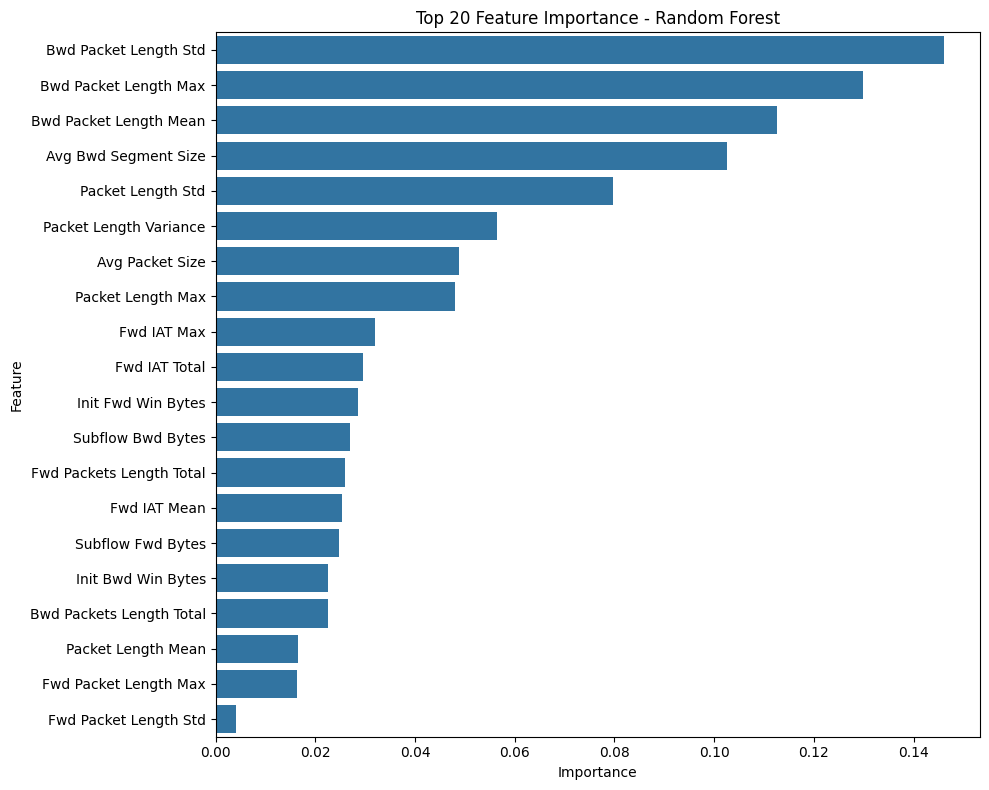

In [68]:
# ============================================================
# 33. TOP 20 FEATURE IMPORTANCE
# ============================================================

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 20 Feature Importance - Random Forest"
)

plt.tight_layout()
plt.show()

In [69]:
# ============================================================
# 34. XGBOOST FEATURE IMPORTANCE
# ============================================================

xgb_model = xgb_models["None_seed_42"]

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_importance.head(20)

,Feature,Importance
14,Bwd Packet Length Std,0.422774
1,Bwd Packet Length Mean,0.199836
2,Avg Bwd Segment Size,0.199448
0,Avg Packet Size,0.073139
4,Bwd Packets Length Total,0.032664
15,Init Bwd Win Bytes,0.020665
17,Init Fwd Win Bytes,0.006965
3,Subflow Bwd Bytes,0.006115
10,Fwd IAT Total,0.005948
5,Bwd Packet Length Max,0.005703


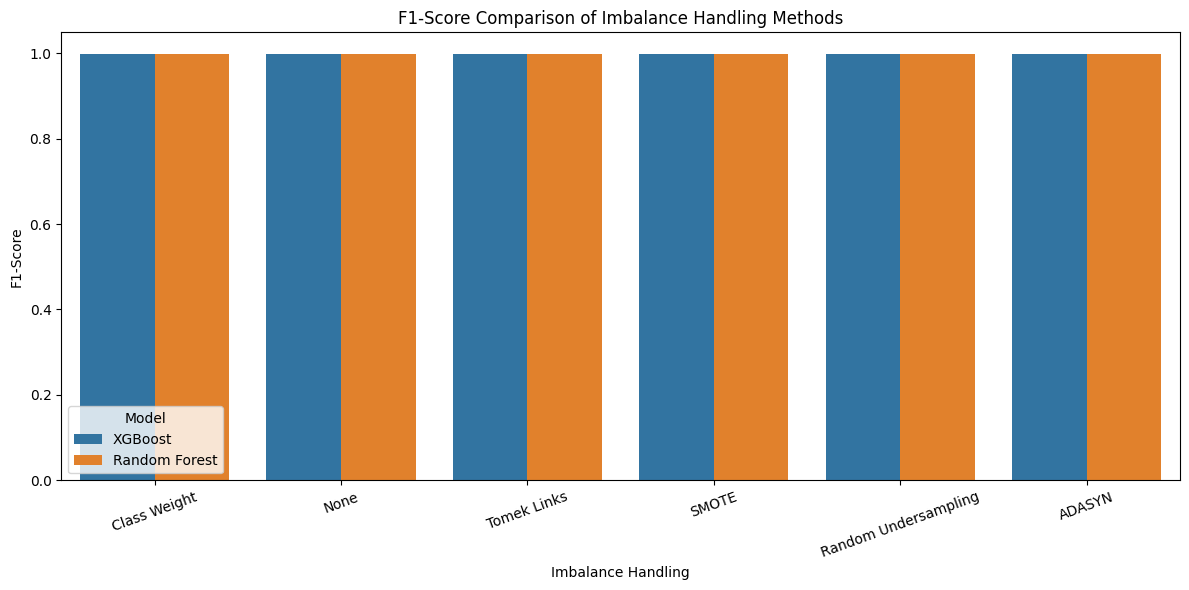

In [70]:
# ============================================================
# 35. F1 COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Handling",
    y="F1",
    hue="Model"
)

plt.xticks(rotation=20)

plt.ylabel("F1-Score")
plt.xlabel("Imbalance Handling")
plt.title(
    "F1-Score Comparison of Imbalance Handling Methods"
)

plt.tight_layout()
plt.show()

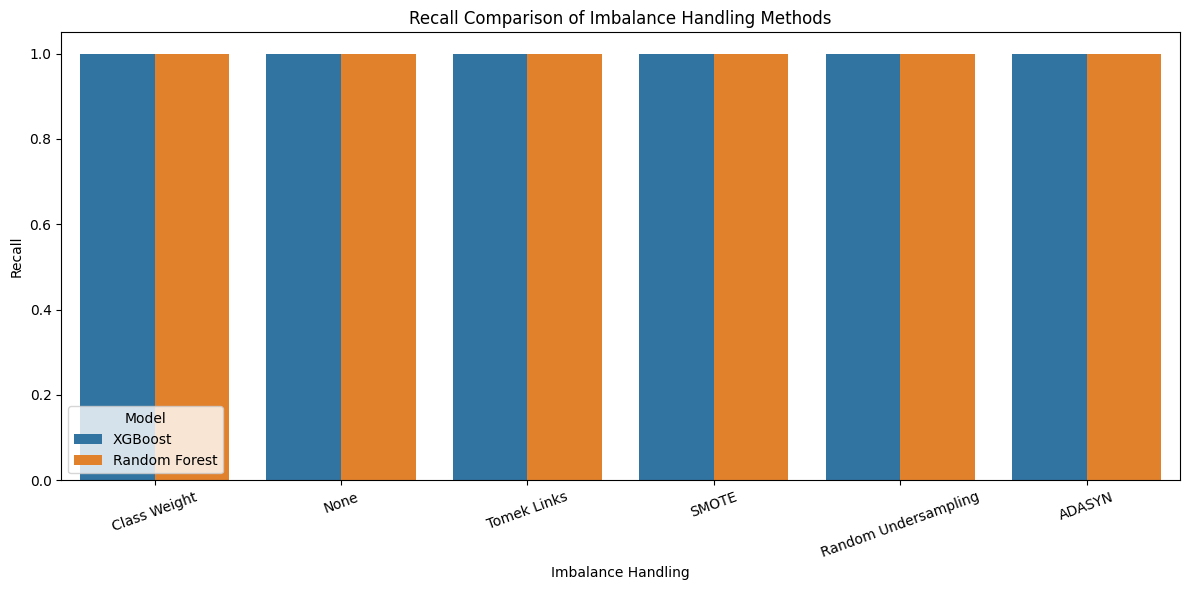

In [71]:
# ============================================================
# 36. RECALL COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Handling",
    y="Recall",
    hue="Model"
)

plt.xticks(rotation=20)

plt.ylabel("Recall")
plt.xlabel("Imbalance Handling")
plt.title(
    "Recall Comparison of Imbalance Handling Methods"
)

plt.tight_layout()
plt.show()

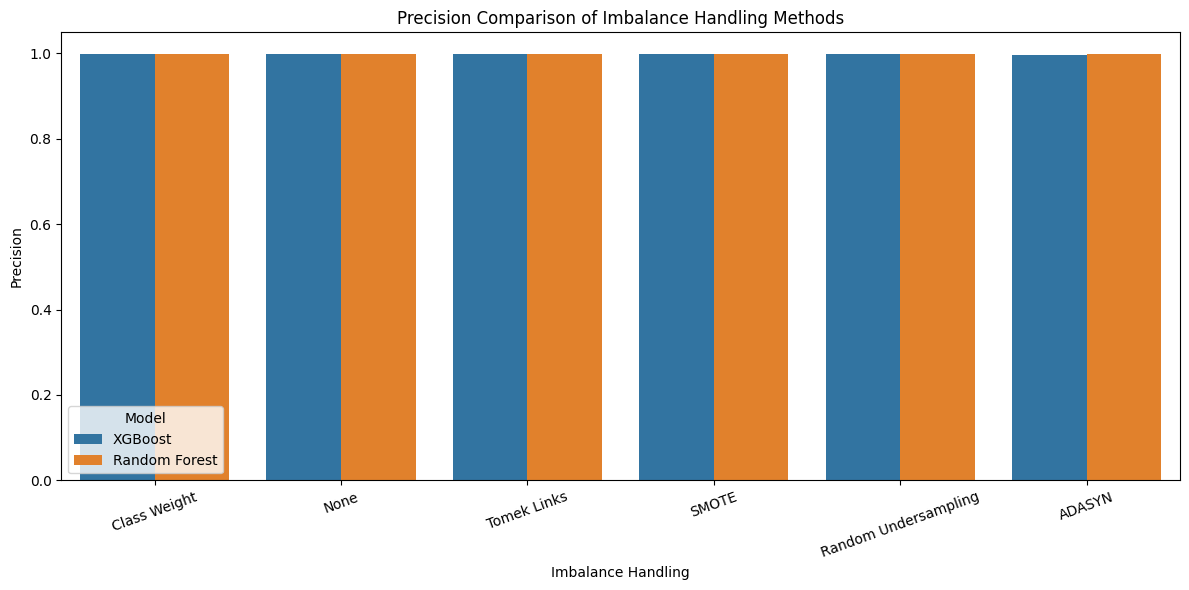

In [72]:
# ============================================================
# 37. PRECISION COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Handling",
    y="Precision",
    hue="Model"
)

plt.xticks(rotation=20)

plt.ylabel("Precision")
plt.xlabel("Imbalance Handling")
plt.title(
    "Precision Comparison of Imbalance Handling Methods"
)

plt.tight_layout()
plt.show()

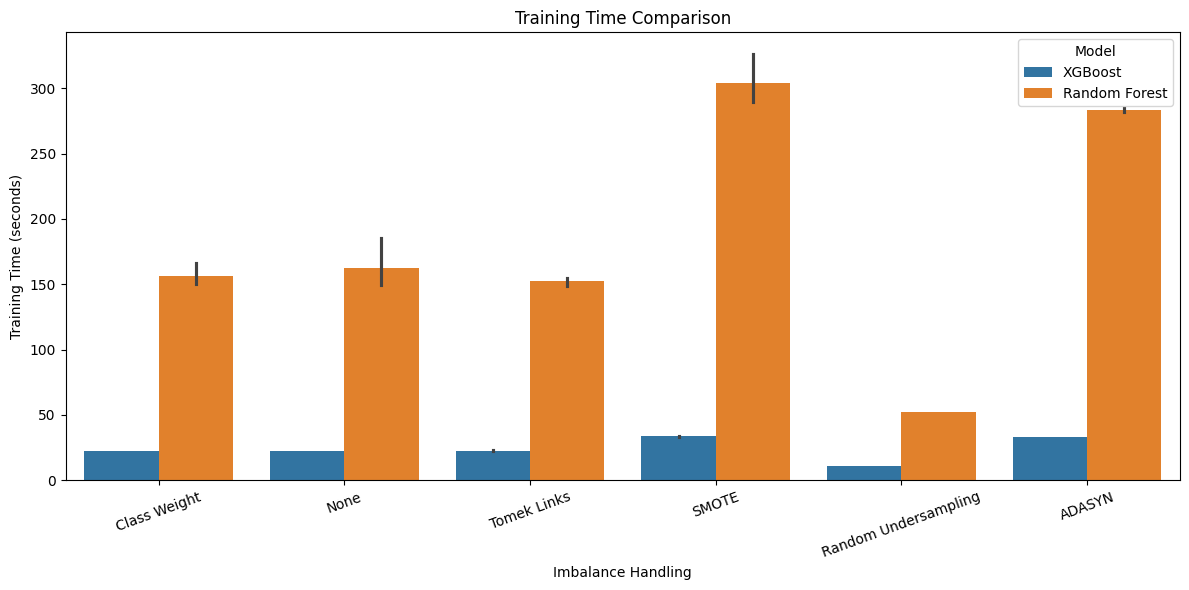

In [73]:
# ============================================================
# 38. TRAINING TIME
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Handling",
    y="Training_Time_sec",
    hue="Model"
)

plt.xticks(rotation=20)

plt.ylabel("Training Time (seconds)")
plt.xlabel("Imbalance Handling")
plt.title(
    "Training Time Comparison"
)

plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# 39. SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance.to_csv(
    "rf_feature_importance.csv",
    index=False
)

xgb_importance.to_csv(
    "xgb_feature_importance.csv",
    index=False
)

print("Feature importance berhasil disimpan.")

Feature importance berhasil disimpan.


In [75]:
results_df[
    [
        "Model",
        "Handling",
        "Seed",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC",
        "Training_Time_sec"
    ]
]

,Model,Handling,Seed,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_sec
0,XGBoost,Class Weight,2024,0.999589,0.998696,0.999689,0.999192,0.999991,0.999977,22.646092
1,XGBoost,Class Weight,123,0.999585,0.998681,0.999689,0.999185,0.999989,0.999975,22.363186
2,XGBoost,None,42,0.999573,0.998804,0.999518,0.999161,0.999992,0.999979,22.718593
3,XGBoost,None,123,0.999569,0.998789,0.999518,0.999153,0.999992,0.999978,22.163242
4,XGBoost,Class Weight,42,0.999565,0.998618,0.999674,0.999146,0.999989,0.999975,22.706523
5,XGBoost,None,2024,0.999565,0.998758,0.999534,0.999146,0.999991,0.999977,22.508745
6,Random Forest,Tomek Links,42,0.999545,0.999161,0.999052,0.999106,0.999940,0.999895,154.509331
7,Random Forest,Class Weight,2024,0.999545,0.999238,0.998974,0.999106,0.999924,0.999871,151.693840
8,Random Forest,Class Weight,42,0.999542,0.999269,0.998928,0.999099,0.999924,0.999871,165.922871
9,Random Forest,Class Weight,123,0.999538,0.999192,0.998990,0.999091,0.999924,0.999871,150.518306


In [76]:
summary = (
    results_df
    .groupby(["Model", "Handling"])
    [
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "PR_AUC",
            "Training_Time_sec"
        ]
    ]
    .agg(["mean", "std"])
)

summary

Accuracy           Precision            \
                                        mean       std      mean       std   
Model         Handling                                                       
Random Forest ADASYN                0.999325  0.000005  0.998173  0.000018   
              Class Weight          0.999542  0.000004  0.999233  0.000039   
              None                  0.999505  0.000024  0.999166  0.000045   
              Random Undersampling  0.999378  0.000023  0.998200  0.000086   
              SMOTE                 0.999470  0.000018  0.998835  0.000041   
              Tomek Links           0.999532  0.000014  0.999140  0.000036   
XGBoost       ADASYN                0.998804  0.000036  0.995595  0.000139   
              Class Weight          0.999580  0.000013  0.998665  0.000041   
              None                  0.999569  0.000004  0.998784  0.000024   
              Random Undersampling  0.999455  0.000045  0.998174  0.000166   
              SMOTE                 0.999453  0.000020  0.998241  0.000059   
              Tomek Links           0.999515  0.000008  0.998577  0.000032   

                                      Recall                  F1            \
                                        mean       std      mean       std   
Model         Handling                                                       
Random Forest ADASYN                0.999176  0.000000  0.998675  0.000009   
              Class Weight          0.998964  0.000032  0.999099  0.000008   
              None                  0.998886  0.000055  0.999026  0.000047   
              Random Undersampling  0.999358  0.000032  0.998778  0.000045   
              SMOTE                 0.999083  0.000056  0.998959  0.000036   
              Tomek Links           0.999021  0.000027  0.999081  0.000027   
XGBoost       ADASYN                0.999720  0.000000  0.997653  0.000070   
              Class Weight          0.999684  0.000009  0.999174  0.000025   
              None                  0.999523  0.000009  0.999153  0.000008   
              Random Undersampling  0.999684  0.000009  0.998929  0.000087   
              SMOTE                 0.999612  0.000062  0.998926  0.000040   
              Tomek Links           0.999518  0.000000  0.999047  0.000016   

                                     ROC_AUC                  PR_AUC  \
                                        mean           std      mean   
Model         Handling                                                 
Random Forest ADASYN                0.999906  8.990635e-06  0.999750   
              Class Weight          0.999924  2.044810e-08  0.999871   
              None                  0.999932  1.052255e-07  0.999883   
              Random Undersampling  0.999954  7.771384e-06  0.999915   
              SMOTE                 0.999919  5.508265e-06  0.999856   
              Tomek Links           0.999927  1.193726e-05  0.999876   
XGBoost       ADASYN                0.999986  8.747434e-07  0.999964   
              Class Weight          0.999990  6.292725e-07  0.999976   
              None                  0.999992  6.251050e-07  0.999978   
              Random Undersampling  0.999991  5.249274e-07  0.999977   
              SMOTE                 0.999990  2.473378e-07  0.999975   
              Tomek Links           0.999991  1.456401e-07  0.999975   

                                                 Training_Time_sec             
                                             std              mean        std  
Model         Handling                                                         
Random Forest ADASYN                1.241794e-05        283.265645   1.481960  
              Class Weight          1.588349e-07        156.045006   8.574651  
              None                  3.767512e-07        162.667812  19.714737  
              Random Undersampling  1.088226e-05         52.473683   0.131966  
              SMOTE                 1.356671e-05     